# Verify tripolar ESMF mesh reconstruction (mom6_forge PR #92)

`SupergridBase.reconstruct_from_esmf_mesh` detects tripolar meshes via a
`grid_topology == "tripolar"` global attribute that only `to_esmf_mesh()`
itself writes. The official NCAR `ESMF_mesh_tx2_3v3_*.nc` file has no such
attribute, so reconstruction mis-detects it as plain-cyclic and crashes:

```
ValueError: cannot reshape array of size 259471 into shape (481,540)
```

This notebook patches a *copy* of the official mesh with the missing
attribute, reconstructs a supergrid from it, and checks the result against
the ground-truth native hgrid file for tx2_3v3.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib ipympl

import shutil
import numpy as np
import matplotlib.pyplot as plt
from netCDF4 import Dataset

from mom6_forge.grid import Grid
from mom6_forge._supergrid import SupergridBase

HGRID_PATH = "/glade/campaign/cesm/cesmdata/inputdata/ocn/mom/tx2_3v3/ocean_hgrid_250930.nc"
ESMF_MESH_PATH = "/glade/campaign/cesm/cesmdata/inputdata/ocn/mom/tx2_3v3/ESMF_mesh_tx2_3v3_260305_cdf5.nc"
PATCHED_PATH = "ESMF_mesh_tx2_3v3_patched.nc"

## 1. Reproduce the failure (unpatched file)

In [2]:
try:
    SupergridBase.reconstruct_from_esmf_mesh(ESMF_MESH_PATH)
    print("Unexpected: reconstruction succeeded without patching")
except ValueError as e:
    print(f"Reproduced expected failure: {e}")

Reproduced expected failure: cannot reshape array of size 259471 into shape (481,540)


## 2. Patch a copy with the missing `grid_topology` attribute

In [3]:
shutil.copy(ESMF_MESH_PATH, PATCHED_PATH)

with Dataset(PATCHED_PATH, "a") as nc:
    nc.grid_topology = "tripolar"

print(f"Patched copy written to {PATCHED_PATH}")

Patched copy written to ESMF_mesh_tx2_3v3_patched.nc


## 3. Reconstruct from the patched mesh, and load ground truth from the native hgrid

In [4]:
sg_reconstructed = SupergridBase.reconstruct_from_esmf_mesh(PATCHED_PATH)
sg_true = Grid.from_supergrid(HGRID_PATH).supergrid

print("Reconstructed supergrid shape:", sg_reconstructed.x.shape)
print("Ground-truth supergrid shape: ", sg_true.x.shape)
assert sg_reconstructed.x.shape == sg_true.x.shape, "Shape mismatch!"

/glade/u/home/manishrv/documents/croc/regional_mom_workflows/mom6_forge/mom6_forge/_supergrid.py:870: RuntimeWarning: invalid value encountered in divide
  cosangle = vecdot(v1xv2, v1xv3) / (norm_v1xv2 * norm_v1xv3)
/glade/u/home/manishrv/documents/croc/regional_mom_workflows/mom6_forge/mom6_forge/_supergrid.py:872: RuntimeWarning: invalid value encountered in arccos
  return np.arccos(cosangle)


Reconstructed supergrid shape: (961, 1081)
Ground-truth supergrid shape:  (961, 1081)


## 4. Compare corner (q) and center (t) points

Longitude is compared mod 360 since the ESMF mesh round-trip may shift the
wrap column by a full rotation.

In [5]:
qlon_r, qlat_r = sg_reconstructed.x[::2, ::2], sg_reconstructed.y[::2, ::2]
qlon_t, qlat_t = sg_true.x[::2, ::2], sg_true.y[::2, ::2]

tlon_r, tlat_r = sg_reconstructed.x[1::2, 1::2], sg_reconstructed.y[1::2, 1::2]
tlon_t, tlat_t = sg_true.x[1::2, 1::2], sg_true.y[1::2, 1::2]

q_lon_ok = np.allclose(qlon_r % 360, qlon_t % 360, atol=1e-6)
q_lat_ok = np.allclose(qlat_r, qlat_t, atol=1e-6)
t_lon_ok = np.allclose(tlon_r % 360, tlon_t % 360, atol=1e-6)
t_lat_ok = np.allclose(tlat_r, tlat_t, atol=1e-6)

print(f"q-point lon match: {q_lon_ok}")
print(f"q-point lat match: {q_lat_ok}")
print(f"t-point lon match: {t_lon_ok}")
print(f"t-point lat match: {t_lat_ok}")

assert q_lon_ok and q_lat_ok and t_lon_ok and t_lat_ok, "Coordinate mismatch found!"

q-point lon match: True
q-point lat match: True
t-point lon match: True
t-point lat match: True


## 5. Max absolute error (sanity check magnitude, not just allclose)

In [6]:
def wrapped_diff(a, b):
    d = (a - b + 180) % 360 - 180
    return np.abs(d)

print("max |q lon diff| (deg):", wrapped_diff(qlon_r, qlon_t).max())
print("max |q lat diff| (deg):", np.abs(qlat_r - qlat_t).max())
print("max |t lon diff| (deg):", wrapped_diff(tlon_r, tlon_t).max())
print("max |t lat diff| (deg):", np.abs(tlat_r - tlat_t).max())

max |q lon diff| (deg): 0.0
max |q lat diff| (deg): 0.0
max |t lon diff| (deg): 0.0
max |t lat diff| (deg): 0.0


## 6. Visualize the fold row (top boundary) to eyeball the mirror symmetry

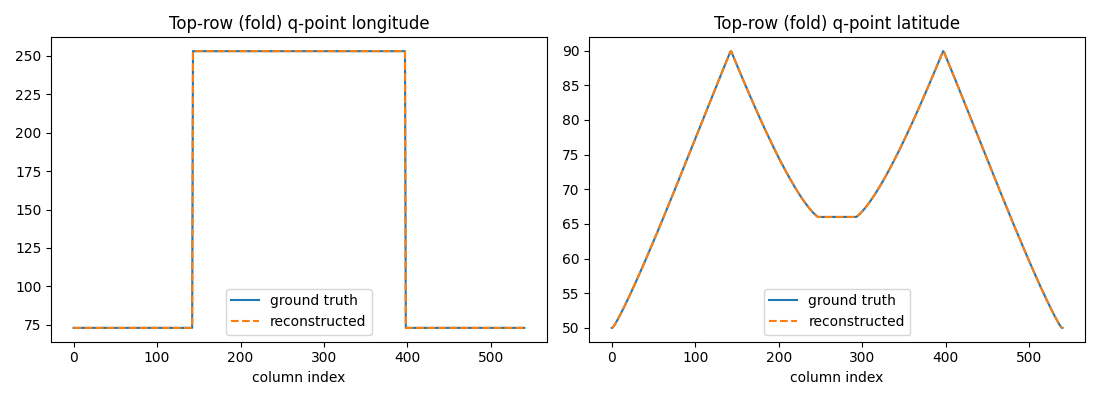

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(qlon_t[-1, :] % 360, label="ground truth")
axes[0].plot(qlon_r[-1, :] % 360, "--", label="reconstructed")
axes[0].set_title("Top-row (fold) q-point longitude")
axes[0].set_xlabel("column index")
axes[0].legend()

axes[1].plot(qlat_t[-1, :], label="ground truth")
axes[1].plot(qlat_r[-1, :], "--", label="reconstructed")
axes[1].set_title("Top-row (fold) q-point latitude")
axes[1].set_xlabel("column index")
axes[1].legend()

plt.tight_layout()

## 7. Check recomputed metrics (`angle_dx`) for NaNs near the fold

`reconstruct_from_esmf_mesh` recomputes dx/dy/area/angle_dx from the
recovered coordinates rather than reading them from file. A
`RuntimeWarning: invalid value encountered in divide/arccos` was observed
during this step -- check whether it produced actual NaNs, and where.

In [8]:
nan_mask = np.isnan(sg_reconstructed.angle_dx)
n_nan = nan_mask.sum()
print(f"angle_dx NaN count: {n_nan} / {sg_reconstructed.angle_dx.size}")
if n_nan:
    rows, cols = np.where(nan_mask)
    print("NaN row range:", rows.min(), "-", rows.max(), "(top row index is", sg_reconstructed.angle_dx.shape[0] - 1, ")")

angle_dx NaN count: 0 / 1038841


## Summary

If all asserts above pass, the tripolar fold-reconstruction math in
`reconstruct_from_esmf_mesh` is correct -- the only defect is topology
*detection*: it should not rely solely on the mom6_forge-specific
`grid_topology` attribute, since real-world ESMF mesh files (including
NCAR's own production tx2_3v3 mesh) don't carry it. A more robust fallback
would infer tripolar layout from node-count arithmetic:
`nodeCount == ny*nx + nx//2 + 1` when `elementCount == ny*nx`.